# Exploring the data

A first look at the two datasets **before** any model is trained:

1. **Wuhan dataset** (iCTCF): single slices, no patient IDs.
2. **Tehran dataset** (COVID-CT-MD): full scans, one folder per patient, with radiologist slice labels.

Run it after `bash scripts/run.sh step0`. The outputs are saved in the notebook, so GitHub shows them.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from covid_ct_diagnosis.data import load_index
from covid_ct_diagnosis.explain import label_sheet

# Relative path to the project folder, whether the notebook runs from the project folder or from 0_data/.
# Relative paths keep local folder names out of the saved outputs
ROOT = Path(".") if Path("0_data").exists() else Path("..")
PROCESSED = ROOT / "0_data" / "processed"

wuhan = load_index(PROCESSED / "ictcf" / "index.csv")
tehran = load_index(PROCESSED / "ctmd" / "index.csv")

In [11]:
# Show a grid of slices, one row per group, with a title on each image
def show_slices(rows_by_group, n_per_row=6, size=2.0):
    fig, axes = plt.subplots(len(rows_by_group), n_per_row, figsize=(size * n_per_row, size * len(rows_by_group)),
                             squeeze=False)
    for r, (group_name, rows) in enumerate(rows_by_group.items()):
        for c in range(n_per_row):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(rows):
                row = rows.iloc[c]
                ax.imshow(Image.open(row["path"]), cmap="gray")
                ax.set_title(f"{group_name}\n{Path(row['path']).name}", fontsize=8)
    fig.tight_layout()
    plt.show()

## 1. Wuhan dataset

Three classes: **nCT** = normal, **pCT** = COVID, **NiCT** = non-informative (the slice shows no lungs, e.g. the neck or the belly).

About 19,700 slices, but they come from only **~104 patients**, and the file names don't say which patient a slice belongs to.

In [12]:
# How many slices per class
wuhan["label"].value_counts().rename("slices").to_frame()

,slices
label,
nCT,9979
NiCT,5705
pCT,4001


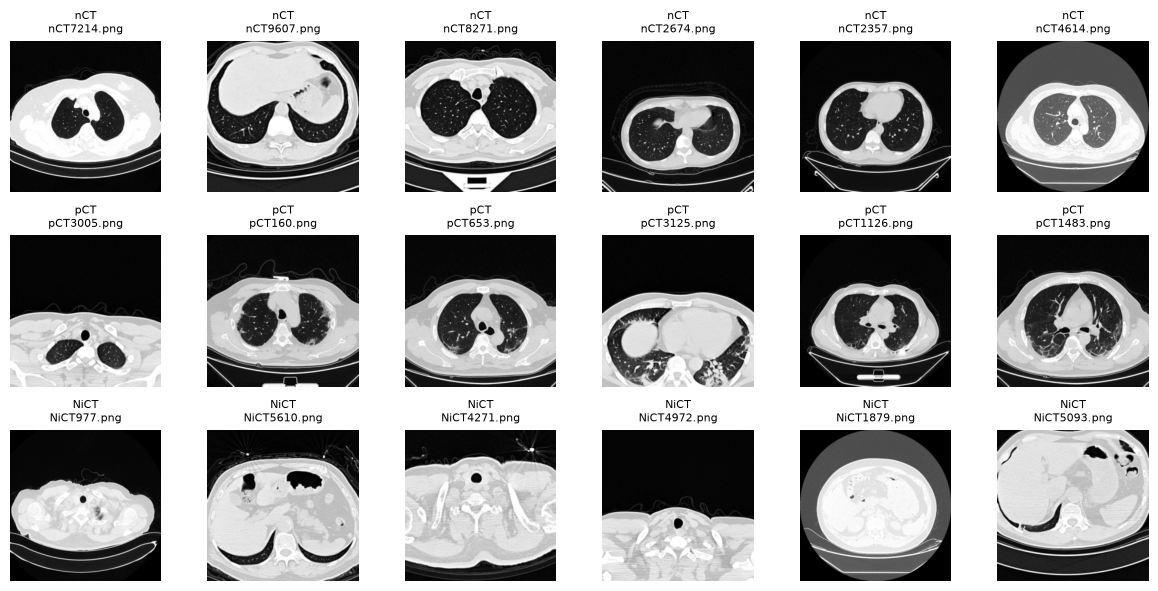

In [13]:
# A few random slices of each class
show_slices({label: wuhan[wuhan["label"] == label].sample(6, random_state=0) for label in ["nCT", "pCT", "NiCT"]})

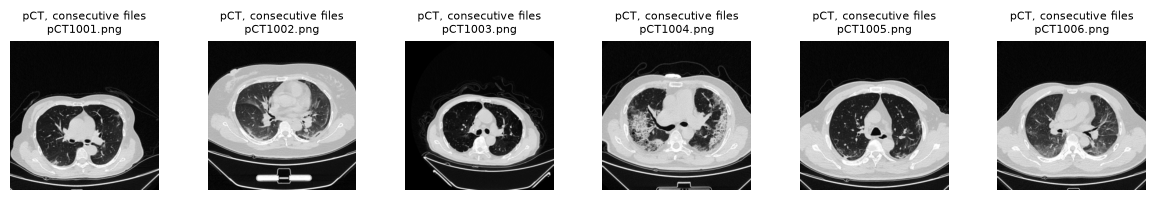

In [14]:
# Do neighbouring file numbers look alike? If they do, they are probably consecutive slices of the same scan,
# and a random split puts one in training and its near-twin in the test set
neighbours = wuhan[wuhan["label"] == "pCT"].sort_values("order").iloc[1000:1006]
show_slices({"pCT, consecutive files": neighbours})

## 2. Tehran dataset

Full CT scans: one folder per patient, so we know which slice belongs to which patient.
Three diagnoses: **COVID-19**, **CAP** (community-acquired pneumonia, i.e. regular pneumonia) and **Normal**.

In [15]:
# Patients per diagnosis, and how many have radiologist slice labels
patients = tehran.groupby("group").agg(
    diagnosis=("diagnosis", "first"),
    slices=("path", "size"),
    has_slice_labels=("label", lambda labels: labels.notna().any()),
)
patients.groupby("diagnosis").agg(
    patients=("slices", "size"),
    with_slice_labels=("has_slice_labels", "sum"),
    median_slices_per_patient=("slices", "median"),
)

,patients,with_slice_labels,median_slices_per_patient
diagnosis,,,
CAP,60,25,151.0
COVID-19,169,54,147.0
Normal,76,76,148.5


In [16]:
# Slice labels: no_lesion = no infection visible, covid / cap = infection visible. Empty = patient without slice labels
tehran["label"].fillna("(no slice label)").value_counts().rename("slices").to_frame()

,slices
label,
(no slice label),22122
no_lesion,18356
covid,3815
cap,1178


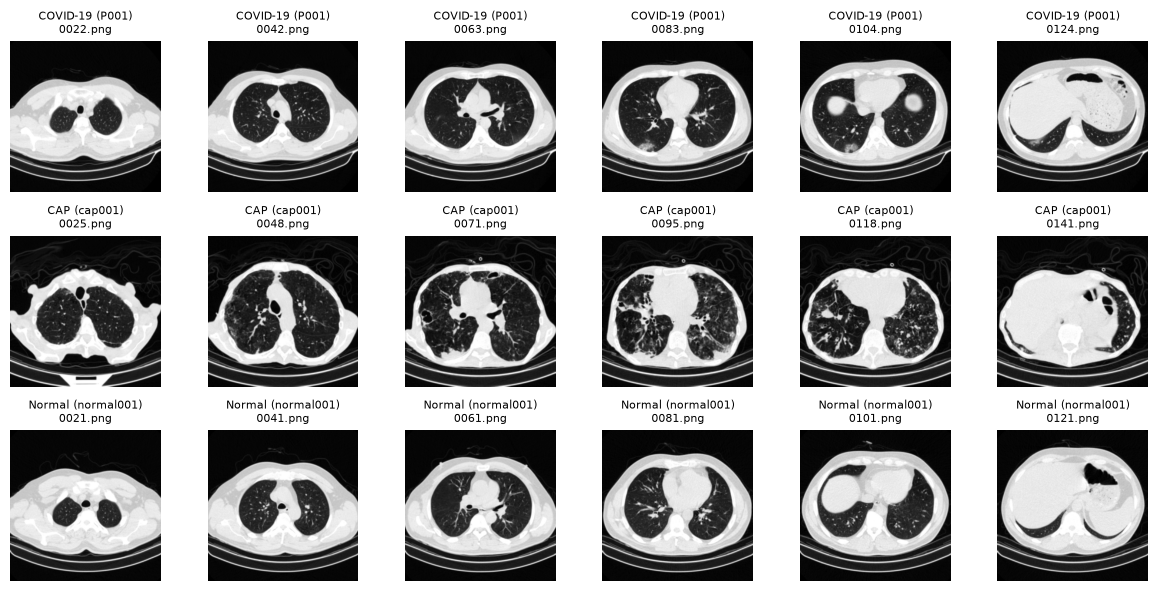

In [17]:
# One patient of each diagnosis, 6 slices from the top of the chest down
examples = {}
for diagnosis in ["COVID-19", "CAP", "Normal"]:
    patient_id = patients[(patients["diagnosis"] == diagnosis) & patients["has_slice_labels"]].index[0]
    slices = tehran[tehran["group"] == patient_id].sort_values("order")
    picks = np.linspace(0.15, 0.85, 6) * (len(slices) - 1)
    examples[f"{diagnosis} ({patient_id})"] = slices.iloc[picks.astype(int)]
show_slices(examples)

## 3. Do the radiologist labels line up with the right slices?

The dataset's instructions say to sort slices by position, but not in which direction.
Here the slices go **from the top of the chest down**. If that's right, the slices framed in red (labelled "infection visible")
should be the ones where the lesions are. For patient `cap002`, they should be near the bottom of the lungs.

saved ../0_data/processed/ctmd/label_check_cap002.png


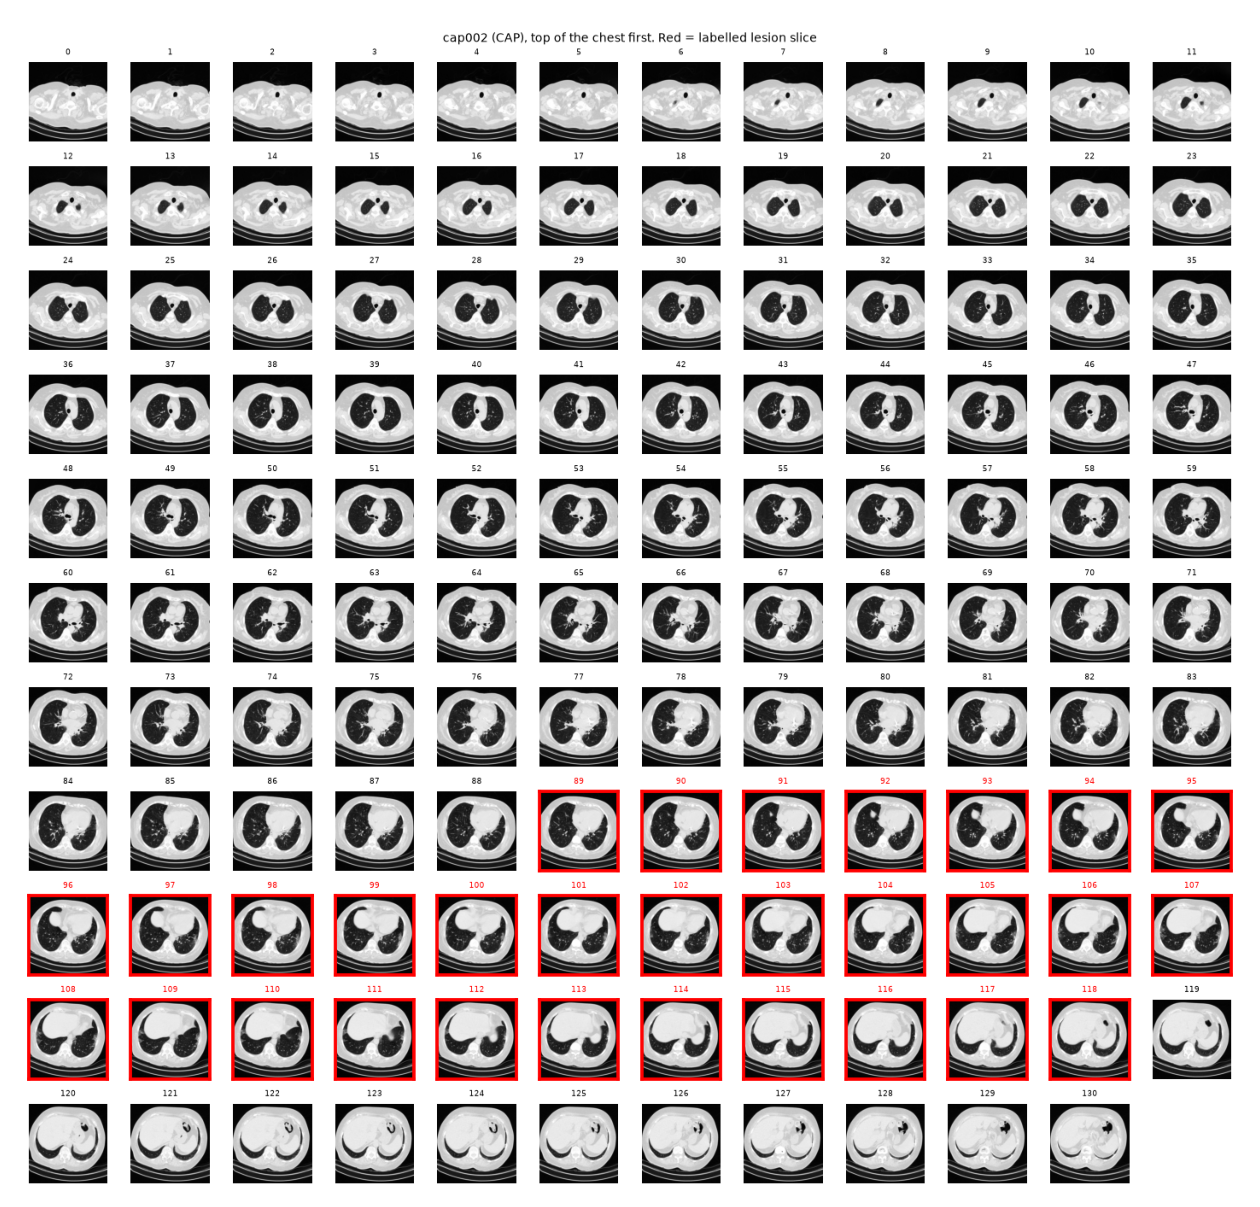

In [18]:
# Contact sheet of every slice of cap002, lesion slices framed in red
sheet = label_sheet(PROCESSED / "ctmd" / "index.csv", "cap002")
plt.figure(figsize=(16, 16))
plt.imshow(Image.open(sheet))
plt.axis("off")
plt.show()

## Takeaways

- Wuhan dataset: many slices but few patients, and no patient IDs, so an honest split is impossible there.
- Tehran: real patient IDs, a pneumonia class, and slice labels for 79 patients. This is the dataset for the honest model.